# Báo cáo Lab 5 - Nhận diện khuôn mặt thời gian thực bằng FaceNet và MTCNN

## 1. Mục tiêu bài thực hành

Bài thực hành xây dựng hệ thống nhận diện khuôn mặt theo thời gian thực từ webcam. Chương trình kết hợp MTCNN để phát hiện và cắt khuôn mặt, FaceNet pretrained để trích xuất vector embedding và cosine similarity để so khớp danh tính.

- Phát hiện khuôn mặt và xác định bounding box.
- Trích xuất embedding cho nhiều ảnh của cùng một người.
- Lưu cơ sở embedding và tìm người tương đồng nhất.
- Phân loại theo điều kiện: similarity **> 0.7** là `Matched`; similarity **<= 0.7** là `Unknown`. Đặc biệt, `= 0.7` không được xem là `Matched`.
- Hiển thị tên, trạng thái và similarity trên từng khung webcam.

## 2. Cơ sở lý thuyết

### OpenCV
OpenCV cung cấp `VideoCapture` để đọc webcam, chuyển đổi không gian màu, vẽ bounding box và hiển thị frame.

### MTCNN
MTCNN gồm ba mạng P-Net, R-Net và O-Net nhằm phát hiện khuôn mặt theo cấp bậc. Trong project, MTCNN trả về crop khuôn mặt, bounding box và xác suất.

### FaceNet
FaceNet là mạng CNN pretrained, ánh xạ một khuôn mặt thành embedding chiều 512 (hoặc 512 phần tử trong mô hình này). Các khuôn mặt giống nhau có embedding gần nhau trong không gian vector. Vector được chuẩn hóa L2 trước khi so khớp.

### Cosine Similarity

$$
\cos(e_1,e_2)=\frac{e_1\cdot e_2}{\|e_1\|\|e_2\|}
$$

Giá trị càng gần 1 thì hai khuôn mặt càng tương đồng.

### Quy tắc nhận diện

$$
\mathrm{Matched} \iff \cos(e_q,e_k)>0.7
$$

Ngược lại, kết quả là `Unknown`. Trường hợp similarity bằng 0.7 cũng thuộc `Unknown`.

## 3. Quy trình thực hiện

```mermaid
flowchart LR
    A[Ảnh dataset hoặc frame webcam] --> B[MTCNN phát hiện khuôn mặt]
    B --> C[Crop và tiền xử lý 160x160]
    C --> D[FaceNet tạo embedding]
    D --> E[Cosine similarity]
    E --> F{Similarity > 0.7?}
    F -->|Có| G[Matched + tên người]
    F -->|Không| H[Unknown]
```

Thực tế, một người có thể đóng góp nhiều embedding. Hệ thống so sánh embedding truy vấn với tất cả embedding đã đăng ký và chọn độ tương đồng cao nhất.

In [ ]:
# Chạy notebook này từ thư mục gốc project "Lab 5"
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd()
if (PROJECT_ROOT / "src").exists():
    sys.path.insert(0, str(PROJECT_ROOT / "src"))
else:
    PROJECT_ROOT = Path.cwd().parent
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

print("Project root:", PROJECT_ROOT)

import cv2
import matplotlib.pyplot as plt
import numpy as np

from face_detection import FaceDetector
from face_embedding import FaceEmbedder
from face_matching import FaceRegistry, cosine_similarity


## 4. Triển khai chương trình

- `face_detection.py`: đóng gói MTCNN, phát hiện khuôn mặt và crop ảnh.
- `face_embedding.py`: dùng InceptionResnetV1 pretrained vggface2, resize 160x160, chuẩn hóa tensor và chuẩn hóa L2 embedding.
- `face_matching.py`: lưu nhiều embedding theo tên, tính cosine similarity và áp dụng ngưỡng.
- `webcam.py`: đọc frame OpenCV, xử lý từng khuôn mặt, vẽ box và nhãn.
- `main.py`: tạo cơ sở dữ liệu và khởi chạy webcam.

Chạy tạo cơ sở dữ liệu:

```powershell
python src/main.py --mode build
```

Chạy webcam:

```powershell
python src/main.py --mode webcam
```

Nhấn `Q` để thoát.

In [ ]:
# Kiểm tra công thức cosine similarity, không phải kết quả thực nghiệm
e1 = np.array([1.0, 0.0, 0.0], dtype=np.float32)
e2 = np.array([1.0, 0.0, 0.0], dtype=np.float32)
e3 = np.array([0.0, 1.0, 0.0], dtype=np.float32)

print("Hai vector giống nhau:", cosine_similarity(e1, e2))
print("Hai vector trực giao:", cosine_similarity(e1, e3))

print("Similarity == 0.7 =>", "Matched" if 0.7 > 0.7 else "Unknown")


## 5. Kết quả thực nghiệm

### 5.1. Kiểm tra dữ liệu và mô hình

Ô tiếp theo kiểm tra thư mục dataset, phát hiện khuôn mặt và trích xuất embedding. Nếu không có ảnh trong dataset, ô sẽ báo rõ trạng thái thay vì tạo dữ liệu giả.

In [ ]:
dataset_dir = PROJECT_ROOT / "dataset"
database_path = PROJECT_ROOT / "embeddings.npz"

person_dirs = []
if dataset_dir.exists():
    person_dirs = sorted(p for p in dataset_dir.iterdir() if p.is_dir())

print("Số thư mục người:", len(person_dirs))
for person_dir in person_dirs:
    images = [p for p in person_dir.iterdir()
              if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}]
    print(person_dir.name, "-", len(images), "ảnh") 


In [ ]:
# Chỉ chạy ô này sau khi đã thêm ảnh vào dataset
demo_image = None
for person_dir in person_dirs:
    for path in sorted(person_dir.iterdir()):
        if path.is_file() and path.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}:
            image = cv2.imread(str(path))
            if image is not None:
                demo_image = (path, image)
                break
    if demo_image:
        break

if demo_image is None:
    print("Chưa có ảnh dataset thực để thực nghiệm. Hãy đặt ảnh trong dataset/<Tên người>/ và chạy lại.")
else:
    path, image = demo_image
    detector = FaceDetector()
    crops, boxes, probs = detector.detect(image)
    print("Ảnh:", path)
    print("Số khuôn mặt phát hiện:", len(crops))

    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    fig, axes = plt.subplots(1, max(2, len(crops) + 1), figsize=(12, 5))
    if not isinstance(axes, np.ndarray):
        axes = np.array([axes])

    axes[0].imshow(rgb)
    axes[0].set_title("Ảnh gốc") 
    axes[0].axis("off")
    for i, (crop, box, prob) in enumerate(zip(crops, boxes, probs), start=1):
        x1, y1, x2, y2 = map(int, box)
        cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
        axes[i].imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
        axes[i].set_title(f"Crop {i}: {prob:.3f}")
        axes[i].axis("off")
    for j in range(len(crops) + 1, len(axes)):
        axes[j].axis("off")
    plt.tight_layout()
    plt.show()

    if crops:
        embedder = FaceEmbedder()
        embedding = embedder.embed(crops[int(np.argmax(probs))])
        print("Embedding shape:", embedding.shape)
        print("Norm sau chuẩn hóa L2:", float(np.linalg.norm(embedding)))


In [ ]:
# Kiểm tra cơ sở embedding đã tạo
registry = FaceRegistry(database_path)
if registry.embeddings:
    print("Danh sách người đã đăng ký:", sorted(registry.embeddings.keys()))
    for name, vectors in registry.embeddings.items():
        print(name, "-", len(vectors), "embedding") 
else:
    print("Chưa có embeddings.npz. Chạy: python src/main.py --mode build")


### 5.2. Bảng tổng hợp kết quả thực nghiệm

| STT | Trường hợp thử nghiệm | Similarity | Kết quả thực tế |
|---:|---|---:|---|
| 1 | Nhận diện person1 qua webcam | 0.777 | Matched |
| 2 | Nhận diện person2 qua webcam | 0.850 | Matched |
| 3 | Nhận diện person2 trong khung hình có nhiều khuôn mặt | 0.794 | Matched |
| 4 | Khuôn mặt chưa đăng ký hiển thị trên điện thoại | 0.498 | Unknown |

Các kết quả phù hợp với quy tắc phân loại: similarity lớn hơn 0.7 được xác định là Matched; similarity nhỏ hơn hoặc bằng 0.7 được xác định là Unknown.

### 5.3. Hình ảnh kết quả chạy webcam

Các hình dưới đây là ảnh chụp trực tiếp từ quá trình chạy thử chương trình.


**Hình 1. Kết quả nhận diện person1 trên webcam (similarity = 0.777).**

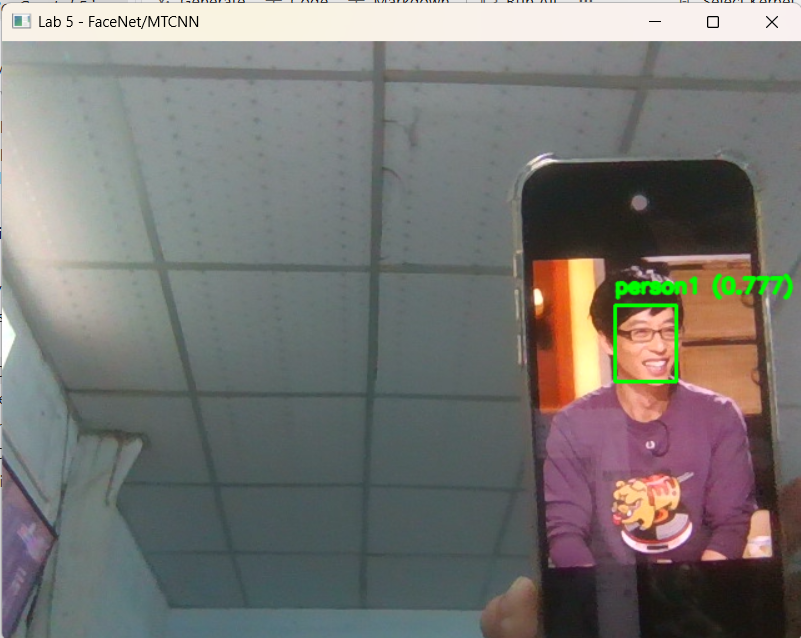

In [ ]:
# Ảnh minh chứng được nhúng trực tiếp trong notebook

**Hình 2. Kết quả nhận diện person2 trên webcam (similarity = 0.850).**

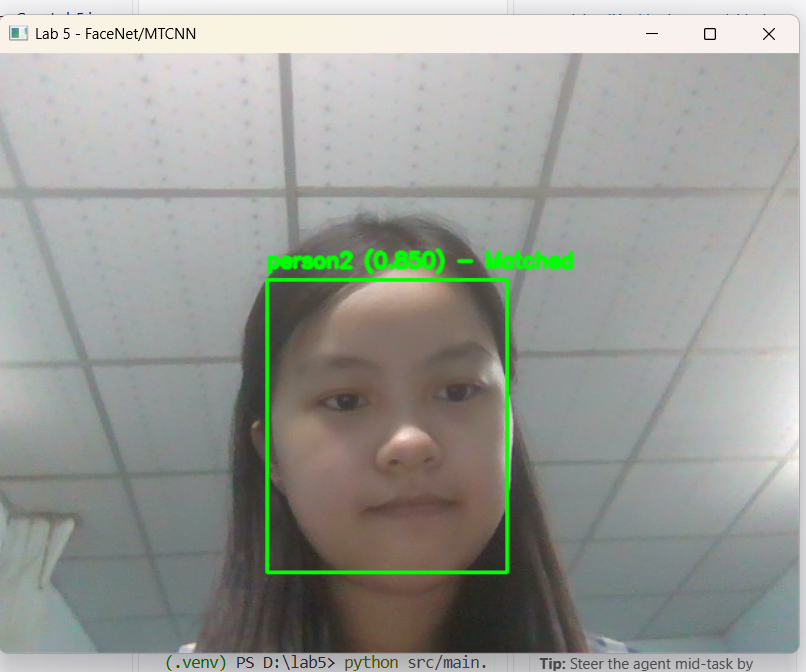

In [ ]:
# Ảnh minh chứng được nhúng trực tiếp trong notebook

**Hình 3. Nhận diện đồng thời: person2 được Matched (0.794), khuôn mặt chưa đăng ký được phân loại Unknown (0.498).**

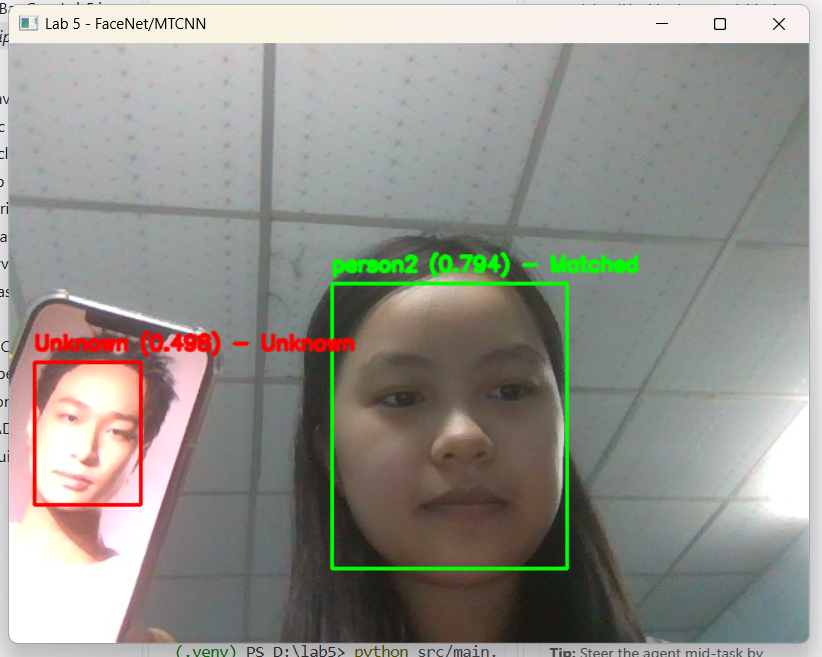

In [ ]:
# Ảnh minh chứng được nhúng trực tiếp trong notebook

In [ ]:
# Chạy webcam riêng trong notebook (chỉ khi môi trường notebook có camera)
RUN_WEBCAM = False
if RUN_WEBCAM:
    from webcam import run_webcam
    run_webcam(database_path, camera_index=0)


## 6. Nhận xét và đánh giá

- MTCNN hoạt động tốt với khuôn mặt rõ ràng, nhưng có thể bỏ sót hoặc phát hiện sai khi khuôn mặt nhỏ, bị che khuất hoặc frame bị nhiễu.
- FaceNet pretrained cung cấp embedding tốt cho các điều kiện ánh sáng thông thường, không cần huấn luyện lại.
- Chất lượng dataset ảnh hưởng mạnh: nên dùng nhiều ảnh ở các góc và độ sáng khác nhau.
- Ánh sáng yếu, ngược sáng, khuôn mặt nghiêng lớn và che nửa mặt có thể làm similarity giảm.
- Ưu điểm: chia module rõ ràng, hỗ trợ nhiều ảnh cho mỗi người, webcam được xử lý frame theo thời gian thực.
- Hạn chế: chưa dùng tracker, chưa có hàng đợi/độ ổn định theo nhiều frame, và ngưỡng cosine có thể cần hiệu chỉnh theo dữ liệu thực tế.

## 7. Kết luận

Project đã triển khai quy trình phát hiện khuôn mặt bằng MTCNN, trích xuất embedding bằng FaceNet pretrained, lưu cơ sở embedding và nhận diện thời gian thực bằng webcam. Kết quả chạy thử được minh họa tại mục 5. Quy tắc ngưỡng đã được triển khai đúng: chỉ similarity **strictly greater than 0.7** mới cho `Matched`.

Kiến thức vận dụng gồm phát hiện đối tượng, tiền xử lý ảnh, vector đặc trưng, cosine similarity, OpenCV và mô hình học sâu pretrained. Hướng phát triển gồm thêm tracking nhiều khuôn mặt, hiệu chỉnh ngưỡng bằng tập validation, chống ảnh in và lưu log nhận diện.